# 50장 · 인용 오류 수정과 회귀 검증

오류를 고친 뒤에는 원래 실패한 문항과 이전부터 성공하던 문항을 함께 실행합니다. 이를 통해 수정이 다른 답변에 미친 영향을 찾습니다.

보류 후보는 p3을 찾아놓고 p2를 인용했습니다. 검색 결과는 그대로 둔 채 반환한 원문의 ID로 고정 답변을 만드는 수정을 재현합니다. 같은 Q03에서 답과 출처가 다시 맞는지 확인하세요.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요.


## 검색한 원문에서 인용 생성

수정 기록 CH50-01｜입력은 Q03, 검색 정책은 error_keyword, 기대 출처는 course-guide-v1:p3입니다. 이전 생성기는 언제나 p2를 붙였습니다. 수정 후보는 원문 본문과 해당 문서 ID를 함께 읽습니다. 이 예시는 미리 작성한 생성 규칙을 고치는 사례입니다.

<!-- lesson-visual detail-fix-id -->
**답변 끝에 고정한 p2를 어떤 값으로 바꿀까요?**

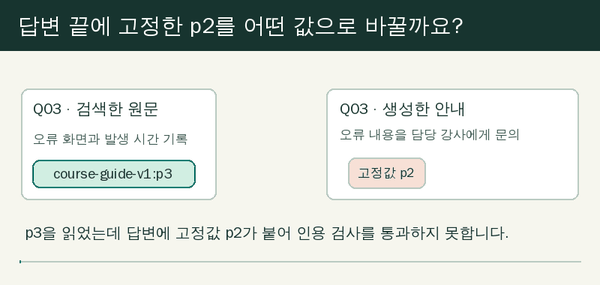

Q03의 오류 안내는 p3에서 검색됐습니다. 생성 규칙이 그 문단의 본문과 ID를 함께 읽으면 표시되는 인용도 p3이 됩니다. 이어지는 회귀 검사에서는 Q01이 기존 결과와 같은지도 확인합니다.
<!-- /lesson-visual detail-fix-id -->


### 셀 01 · 검색 원문에서 답변 구성

가상 문서의 오류 대응 절차와 인용 ID를 같은 객체에서 꺼냅니다.


In [1]:
evidence = {'id': 'course-guide-v1:p3',
 'text': '제출 오류가 발생하면 오류 화면과 발생 시간을 기록하고 담당 강사에게 문의합니다. 비밀키가 보이는 화면은 공유하지 '
         '않습니다.',
 'source': '가상 과정 운영 안내 · 45일 수업용 페이지판 (source-pages.html)',
 'page': 1}
answer = f"모의 응답: {evidence['text']} [{evidence['id']}]"
print(answer)

모의 응답: 제출 오류가 발생하면 오류 화면과 발생 시간을 기록하고 담당 강사에게 문의합니다. 비밀키가 보이는 화면은 공유하지 않습니다. [course-guide-v1:p3]


화면·시간 기록, 강사 문의, 비밀키가 보이는 화면의 공유 금지까지 원문에 있습니다. 끝의 p3 인용이 올바른지와 문장의 뜻이 보존됐는지를 각각 확인하세요.


## 기존 성공 문항의 회귀 검사

새 답 한 건이 맞아도 기존 답변이 바뀌었을 수 있습니다. 제공 회귀표의 R50-Q01은 Q01의 수정 전후 결과를 기준선과 대조합니다. Q02의 점수 문의와 Q04의 주말 일정은 여전히 자료에서 확인할 수 없다고 안내해야 합니다.


### 수정한 실패 사례에서 기존 정상 문항으로 돌아가기

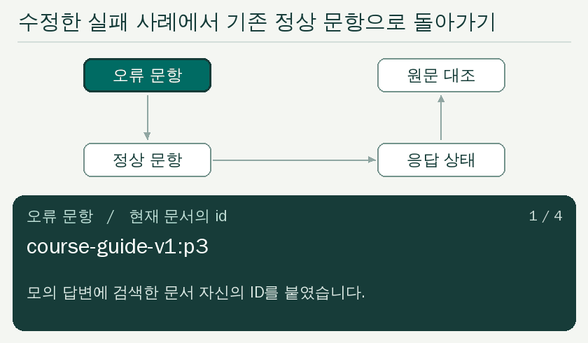

오류 문항의 인용을 고친 뒤 기존에 성공하던 Q01을 다시 봅니다. 자동 비교 결과와 원문 의미 확인을 함께 읽으세요.


### 셀 02 · 기존 정상 문항의 회귀 결과

기존 동작을 비교한 결과와 사람의 의미 검토 범위를 읽습니다.

Q01 답에 붙은 p2를 열고 ‘과제함’이라는 장소가 원문의 제출 위치와 같은지 읽으세요. ID가 맞는지는 코드로 검사할 수 있지만, 문장이 같은 뜻인지 판단한 사람만 meaning_review를 마쳤다고 적습니다.


In [2]:
regression = {'question_id': 'Q01',
 'same_A1_as_baseline': True,
 'observed_status_after': 'answered',
 'meaning_review': 'requires_direct_source_reading'}
print(regression['question_id'], regression['same_A1_as_baseline'], regression['observed_status_after'])

Q01 True answered


Q01의 응답 객체는 기준선과 같고 상태는 answered입니다. 팀에서 수정할 때는 문제 문항과 영향받지 않아야 할 문항을 함께 정하세요. 기준선에서 최종 후보까지는 검색과 생성 두 변경이 누적되므로 생성만 고친 비교는 보류 후보부터 시작합니다.


## 돌아보기

이 후보는 공개 질문 네 건의 로컬 회귀만 확인했습니다. 새로운 질문, 실제 모델, 동료 사용자에게도 같은 결과인지는 별도로 확인할 항목입니다.
